In [1]:
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt

In [2]:
csv_files = glob.glob(os.path.join('202608-citibike-tripdata', "*.csv"))

df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)

print(df.shape)
df.head()

/var/folders/qd/92q86s8s6l51v7_qfzdpgvr00000gn/T/ipykernel_38205/1227029698.py:3: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)
/var/folders/qd/92q86s8s6l51v7_qfzdpgvr00000gn/T/ipykernel_38205/1227029698.py:3: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)
/var/folders/qd/92q86s8s6l51v7_qfzdpgvr00000gn/T/ipykernel_38205/1227029698.py:3: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)
/var/folders/qd/92q86s8s6l51v7_qfzdpgvr00000gn/T/ipykernel_38205/1227029698.py:3: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.concat([pd.read_csv(file)

(5246236, 13)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,8DE28BB8DE7E7B37,classic_bike,2026-08-08 13:09:07.617,2026-08-08 13:56:43.819,7 Ave S & Bleecker St,5805.07,Murray St & West St (NW Corner),5329.09,40.732139,-74.003638,40.715438,-74.014077,casual
1,26D1DFF0A7C10B8E,classic_bike,2026-08-06 08:18:45.376,2026-08-06 08:44:50.952,Ave C & McDonald Ave,2957.08,West Drive & Prospect Park West,3651.04,40.640344,-73.979152,40.661063,-73.979453,member
2,D3C1E6BE59C03672,classic_bike,2026-08-04 08:13:55.475,2026-08-04 08:41:50.638,Ave C & McDonald Ave,2957.08,West Drive & Prospect Park West,3651.04,40.640344,-73.979152,40.661063,-73.979453,member
3,896AB31C4062E923,electric_bike,2026-08-06 08:25:17.381,2026-08-06 08:44:10.849,W 52 St & 11 Ave,6926.01,Murray St & West St (NW Corner),5329.09,40.767272,-73.993929,40.715438,-74.014077,member
4,0D9343B067B9A8C1,electric_bike,2026-08-01 18:50:22.934,2026-08-01 18:54:29.064,Hancock St & Malcolm X Blvd,4342.04,Halsey St & Tompkins Ave,4319.07,40.684870,-73.929300,40.682369,-73.944118,member


### Warm Up

1. Using the start and end times, compute each ride’s duration in minutes and plot a histogram
of ride durations.


Text(0, 0.5, 'Frequency')

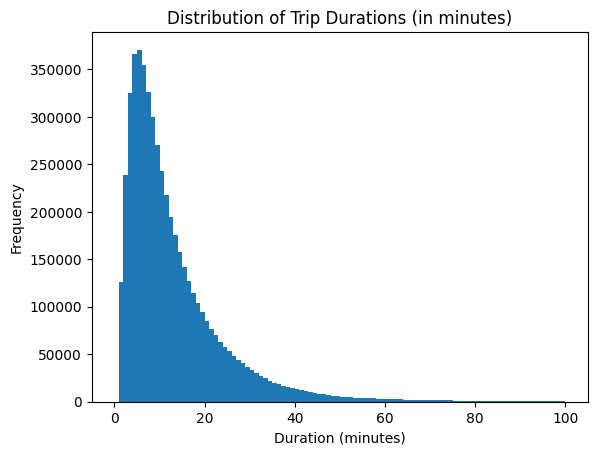

In [3]:
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])

df['duration_min'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

plt.hist(df['duration_min'], bins=100, range=(0, 100))
plt.title('Distribution of Trip Durations (in minutes)')
plt.xlabel('Duration (minutes)')
plt.ylabel('Frequency')

2. What is the expected ride duration (the average ride duration)? What is the empirical variance
of ride duration? What is the probability that a ride lasts more than 20 minutes?

In [4]:
average_duration = df['duration_min'].mean()
duration_variance = df['duration_min'].var()
prob_greater_20 = df[df['duration_min'] > 20].shape[0] / df.shape[0]


print(f'Average trip duration: {average_duration} minutes')
print(f"Variance of trip durations: {duration_variance} minutes^2")
print(f"Probability of trip duration > 20 minutes: {prob_greater_20}")

Average trip duration: 14.21215479715044 minutes
Variance of trip durations: 922.0177606866746 minutes^2
Probability of trip duration > 20 minutes: 0.1900507335163725


3. What is the probability that a ride lasts more than 20 minutes conditional on the user being
a Citi Bike member?

In [6]:
citibike_member = df[df['member_casual'] == 'member']
prob_greater_20_member = citibike_member[citibike_member['duration_min'] > 20].shape[0] / citibike_member.shape[0]

print(f"Probability of trip duration > 20 minutes given citibike member: {prob_greater_20_member}")

Probability of trip duration > 20 minutes given citibike member: 0.15452431214691942


4. Suppose that a ride lasts more than 25 minutes. What is the probability that this ride belongs
to a Citi Bike member?

In [7]:
ride_over_25 = df[df['duration_min'] > 25]
prob_citi_member = ride_over_25[ride_over_25['member_casual'] == 'member'].shape[0] / ride_over_25.shape[0]

print(f'Probability of being a citibike member given the trip duration > 25 minutes: {prob_citi_member}')

Probability of being a citibike member given the trip duration > 25 minutes: 0.5995875265549163


5. What is the expected ride duration of an electric bike? What is the expected ride duration of
a classic bike?

In [8]:
electric_bike_mean = df[df['rideable_type'] == 'electric_bike']['duration_min'].mean()
classic_bike_mean = df[df['rideable_type'] == 'classic_bike']['duration_min'].mean()

print(f'Average trip duration for electric bikes: {electric_bike_mean} minutes')
print(f'Average trip duration for classic bikes: {classic_bike_mean} minutes')

Average trip duration for electric bikes: 13.66052541987006 minutes
Average trip duration for classic bikes: 15.70779108804206 minutes


6. Suppose that a ride lasts less than 10 minutes. What is the probability that it uses an electric
bike? What is the probability that it uses a classic bike? Comment on the results.

In [10]:
ride_under_10 = df[df['duration_min'] < 10]
prob_classic_given_under_10 = ride_under_10[ride_under_10['rideable_type'] == 'classic_bike'].shape[0] / ride_under_10.shape[0]
prob_electric_given_under_10 = ride_under_10[ride_under_10['rideable_type'] == 'electric_bike'].shape[0] / ride_under_10.shape[0]

print(f'Probability of being a classic bike user given the trip duration < 10 minutes: {prob_classic_given_under_10}')
print(f'Probability of being an electric bike user given the trip duration < 10 minutes: {prob_electric_given_under_10}')

Probability of being a classic bike user given the trip duration < 10 minutes: 0.2795684954163652
Probability of being an electric bike user given the trip duration < 10 minutes: 0.7204315045836348


Given the trip duration is less than 10 minutes, the probability that the bike is electric is much higher than it being a classic bike, most likely becuase electric bikes are faster so it takes less time to get places.